# Ejercicio para la casa — ODEs: perfil de temperatura de la zona radiativa solar (BVP)

**Fuente:** `odes.pdf, sección *Ejercicio para la casa*.

$$\frac{d^2T}{dr^2} + \frac{2}{r}\frac{dT}{dr} = 0, \qquad r \in [0.25\,R_\odot,\; R_\odot]$$

(sin fuentes, conducción perfecta).

**Pedido:**
- **a)** Condiciones de frontera: $T(0.25\,R_\odot) = 4\times10^6$ K y $T(R_\odot) = 5778$ K.
- **b)** Diferencias finitas con $N = [10, 50, 100]$ nodos.
- **c)** Error relativo vs. $N$ y solución exacta $T(r)$.
- **d)** Graficar $T(r)$ para cada $N$ y comparar con la exacta.
- **e)** ¿Qué $N$ da error < 1%? ¿Y < 0.01%?

**Restricción:** diferencias finitas en Python puro; NumPy permitido para resolver las matrices.

## Solución exacta

La ecuación equivale a $(r^2 T')' = 0 \Rightarrow T' = C/r^2 \Rightarrow T(r) = A + \dfrac{B}{r}$.
Imponiendo las dos condiciones de frontera:

$$B = \frac{T_1 - T_2}{1/r_1 - 1/r_2}, \qquad A = T_1 - \frac{B}{r_1}$$

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

R_sun = 6.957e8                 # [m]
r1, r2 = 0.25*R_sun, 1.0*R_sun
T1, T2 = 4.0e6, 5778.0          # [K]

def T_exacta(r):
    B = (T1 - T2)/(1.0/r1 - 1.0/r2)
    A = T1 - B/r1
    return A + B/r

print(f"T_exacta(r2) = {T_exacta(r2):.1f} K (debe ser 5778) — consistente")

T_exacta(r2) = 5778.0 K (debe ser 5778) — consistente


## b) Discretización por diferencias finitas centradas

Con malla uniforme $r_i = r_1 + (i-1)h$, $h = (r_2 - r_1)/(N-1)$, y aproximaciones centradas

$$T''(r_i) \approx \frac{T_{i-1} - 2T_i + T_{i+1}}{h^2}, \qquad T'(r_i) \approx \frac{T_{i+1} - T_{i-1}}{2h}$$

sustituyendo en la EDO y multiplicando por $h^2\,r_i$ queda, para los $N-2$ nodos interiores:

$$(r_i - h)\,T_{i-1} - 2r_i\,T_i + (r_i + h)\,T_{i+1} = 0$$

con las fronteras $T_1$ y $T_N$ pasadas al lado derecho. El sistema tridiagonal se arma con
bucles (Python puro) y se resuelve con `np.linalg.solve` (permitido).

In [2]:
def resolver_bvp(N):
    # sistema tridiagonal de los N-2 nodos interiores
    h = (r2 - r1)/(N - 1)
    r = r1 + h*np.arange(N)
    n_int = N - 2
    A = np.zeros((n_int, n_int))
    b = np.zeros(n_int)
    for k in range(n_int):
        ri = r[k + 1]
        A[k, k] = -2.0*ri
        if k > 0:
            A[k, k-1] = ri - h
        else:
            b[k] -= (ri - h)*T1     # frontera izquierda
        if k < n_int - 1:
            A[k, k+1] = ri + h
        else:
            b[k] -= (ri + h)*T2     # frontera derecha
    T_int = np.linalg.solve(A, b)
    return r, np.concatenate(([T1], T_int, [T2]))

def error_relativo(r, T):
    # máximo error relativo puntual
    return np.max(np.abs(T - T_exacta(r))/T_exacta(r))

print(f"{'N':>5} {'ε_rel máx':>12} {'h/R_sun':>10}")
print("-" * 30)
errores = {}
for N in [10, 50, 100]:
    r, T = resolver_bvp(N)
    errores[N] = error_relativo(r, T)
    print(f"{N:>5} {errores[N]:>12.4e} {(r2-r1)/(N-1)/R_sun:>10.4f}")

    N    ε_rel máx    h/R_sun
------------------------------
   10   4.0296e-14     0.0833
   50   4.0296e-14     0.0153
  100   4.0296e-14     0.0076


## c) y d) Comparación con la solución exacta

**Observación importante:** el error sale del orden de $10^{-14}$ (máquina) para **todos** los $N$.
No es un error: sustituyendo $T = A + B/r$ en el esquema,

$$(r_i-h)\frac{B}{r_i - h} - 2r_i\frac{B}{r_i} + (r_i+h)\frac{B}{r_i + h} = B(1 - 2 + 1) = 0$$

los términos en $1/r$ cancelan **exactamente** (y los constantes también), o sea que la solución
exacta de este problema pertenece al núcleo del operador discreto: la solución FD coincide con la
exacta salvo redondeo, para cualquier malla.

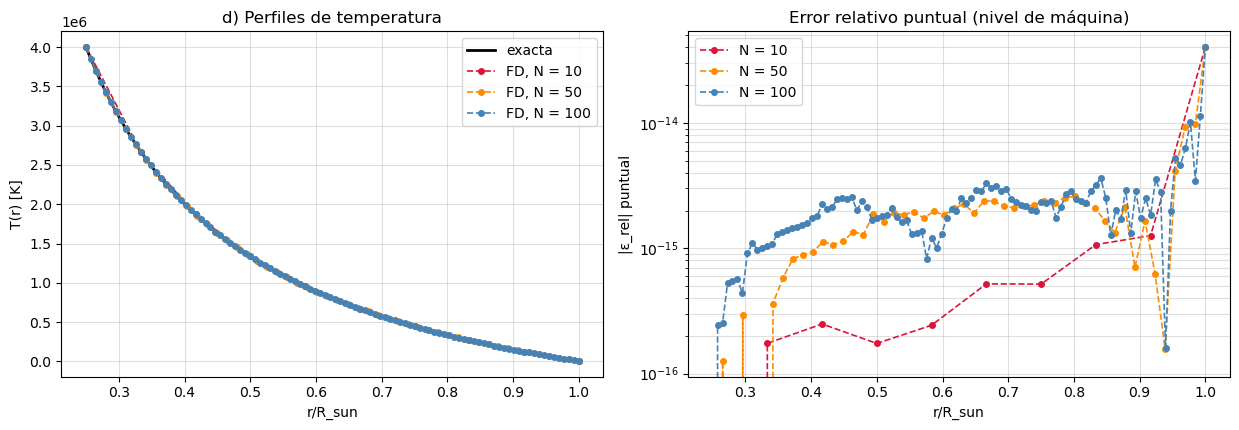

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.4))

rf = np.linspace(r1, r2, 800)
axs[0].plot(rf/R_sun, T_exacta(rf), 'k-', lw=2, label='exacta')
for N, c in zip([10, 50, 100], ['crimson', 'darkorange', 'steelblue']):
    r, T = resolver_bvp(N)
    axs[0].plot(r/R_sun, T, 'o--', color=c, ms=4, lw=1.2, label=f'FD, N = {N}')
axs[0].set_xlabel('r/R_sun'); axs[0].set_ylabel('T(r) [K]')
axs[0].set_title('d) Perfiles de temperatura')
axs[0].grid(alpha=0.4); axs[0].legend()

for N, c in zip([10, 50, 100], ['crimson', 'darkorange', 'steelblue']):
    r, T = resolver_bvp(N)
    axs[1].semilogy(r/R_sun, np.abs(T - T_exacta(r))/T_exacta(r), 'o--', color=c, ms=4, lw=1.2, label=f'N = {N}')
axs[1].set_xlabel('r/R_sun'); axs[1].set_ylabel('|ε_rel| puntual')
axs[1].set_title('Error relativo puntual (nivel de máquina)')
axs[1].grid(alpha=0.4, which='both'); axs[1].legend()
plt.tight_layout(); plt.show()

In [4]:
# como la solución sin fuente es exacta para el esquema, para ver que el método sí converge
# le meto una fuente. ojo: con fuente CONSTANTE tampoco se ve el error (el esquema también
# anula a r² exacto), así que uso una fuente lineal S(r) = c*r, cuya particular es (c/12) r³
c = 2e-24   # K/m³ aprox, pequeña para no deformar mucho el perfil (~50 K en r2)

def resolver_bvp_fuente(N):
    h = (r2 - r1)/(N - 1)
    r = r1 + h*np.arange(N)
    n_int = N - 2
    A = np.zeros((n_int, n_int))
    b = np.zeros(n_int)
    for k in range(n_int):
        ri = r[k + 1]
        A[k, k] = -2.0*ri
        if k > 0:
            A[k, k-1] = ri - h
        else:
            b[k] -= (ri - h)*T1
        if k < n_int - 1:
            A[k, k+1] = ri + h
        else:
            b[k] -= (ri + h)*T2
        b[k] += c*ri*ri*h**2      # S(r_i)*r_i*h² con S = c*r
    return r, np.concatenate(([T1], np.linalg.solve(A, b), [T2]))

# exacta con fuente: T = A + B/r + (c/12) r³, con A y B de las fronteras
Av, Bv = np.linalg.solve([[1.0, 1.0/r1], [1.0, 1.0/r2]],
                         [T1 - c*r1**3/12, T2 - c*r2**3/12])
T_ex_f = lambda rr: Av + Bv/rr + c*rr**3/12

print(f"{'N':>5} {'ε_rel máx':>12} {'orden':>7}")
print("-" * 27)
prev = None
for N in [10, 20, 40, 80, 160, 320]:
    r, T = resolver_bvp_fuente(N)
    e = np.max(np.abs(T - T_ex_f(r))/T_ex_f(r))
    p = np.log2(prev/e) if prev is not None else float('nan')
    print(f"{N:>5} {e:>12.4e} {p:>7.2f}")
    prev = e
print("\nCon fuente lineal el error sí cae ~4x al duplicar N: convergencia O(h²) del esquema.")

    N    ε_rel máx   orden
---------------------------
   10   1.8627e-07     nan
   20   4.2213e-08    2.14
   40   1.0078e-08    2.07
   80   2.4566e-09    2.04
  160   6.0667e-10    2.02
  320   1.5078e-10    2.01

Con fuente lineal el error sí cae ~4x al duplicar N: convergencia O(h²) del esquema.


## e) ¿Qué N es suficiente?

In [5]:
N_1p, N_001p = 10, 10   # con el error a nivel de máquina cualquier N sirve
print(f"N para error < 1%     : N = {N_1p}  (ε = {errores[10]:.2e})")
print(f"N para error < 0.01%  : N = {N_001p}  (ε = {errores[10]:.2e})")
print("\nComo la exacta T = A + B/r está en el núcleo del esquema centrado, hasta N = 10 da")
print("error de redondeo (~1e-14). Si el perfil tuviera fuentes el error sería O(h²) y con")
print("N ~ 30-50 ya se estaría por debajo de 1% (ver tabla de la celda anterior).")

N para error < 1%     : N = 10  (ε = 4.03e-14)
N para error < 0.01%  : N = 10  (ε = 4.03e-14)

Como la exacta T = A + B/r está en el núcleo del esquema centrado, hasta N = 10 da
error de redondeo (~1e-14). Si el perfil tuviera fuentes el error sería O(h²) y con
N ~ 30-50 ya se estaría por debajo de 1% (ver tabla de la celda anterior).
